# PA3: Search over Reasoning
Kaggle T4 x2 pipeline: Qwen2.5-1.5B generator, Qwen2.5-7B (NF4) step judge, GSM8K-50. Designed for unattended Save & Run All execution; all artifacts are written under `/kaggle/working`.

## Setup

In [1]:
import glob
import os
import shutil
import subprocess
import sys

REPO_URL = "https://github.com/syeddaniyalg/cs5326-pa3.git"
REPO = "/kaggle/working/cs5326-pa3"

if os.path.isdir(os.path.join(REPO, ".git")):
    subprocess.run(["git", "-C", REPO, "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, REPO], check=True)
os.chdir(REPO)
sys.path.insert(0, REPO)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "bitsandbytes"], check=True)

restored = []
for source in glob.glob("/kaggle/input/**/checkpoints", recursive=True):
    target = os.path.join(REPO, "outputs", "checkpoints")
    if os.path.isfile(os.path.join(source, "generation.jsonl")) and not os.path.exists(target):
        shutil.copytree(source, target)
        restored.append(source)
print("restored checkpoints from:", restored or "none")

Cloning into '/kaggle/working/cs5326-pa3'...


restored checkpoints from: none


In [2]:
import torch

print("torch", torch.__version__, "| cuda", torch.version.cuda)
for index in range(torch.cuda.device_count()):
    properties = torch.cuda.get_device_properties(index)
    print(f"cuda:{index}", properties.name, f"{properties.total_memory / 1024**3:.1f} GB")
assert torch.cuda.device_count() >= 1, "no GPU visible"

torch 2.11.0+cu130 | cuda 13.0
cuda:0 Tesla T4 14.6 GB
cuda:1 Tesla T4 14.6 GB


## Model download

In [3]:
from src.pipeline import prefetch_models
from src.utils import GENERATOR_ID, JUDGE_ID

prefetch_models([GENERATOR_ID, JUDGE_ID])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

## Pipeline
Generation (greedy, SC-5, SC-15) runs on `cuda:0` while the judge scores the shared 5-path pools on `cuda:1`. Per-problem results are checkpointed to `outputs/checkpoints`, so an interrupted run resumes where it stopped.

In [4]:
import run_all

try:
    artifacts = run_all.main([])
finally:
    archive = shutil.make_archive("/kaggle/working/pa3_outputs", "zip", os.path.join(REPO, "outputs"))
    print("packaged:", archive)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

judge   : 100%|██████████| 50/50 [52:16<00:00, 62.74s/prob, min=70.0%, prod=70.0%, pen=70.0%, K=5.84, invalid=23.9%, s/prob=62.1]


| Method | Accuracy (%) | Generation Calls | Judge Calls | Total LLM Calls | Avg Gen Tokens / Problem | Avg Judge Tokens / Problem | Total Time (s) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Greedy (N=1) | 56.0 | 50 | 0 | 50 | 228.38 | 0.0 | 660.82 |
| Self-Consistency (N=5) | 64.0 | 250 | 0 | 250 | 926.98 | 0.0 | 771.62 |
| Compute-Matched SC (N=15) | 80.0 | 750 | 0 | 750 | 2746.42 | 0.0 | 1677.6 |
| PRM Best-of-5 (min) | 70.0 | 250 | 1459 | 1709 | 926.98 | 914.14 | 3875.2 |
| PRM Best-of-5 (product) | 70.0 | 250 | 1459 | 1709 | 926.98 | 914.14 | 3875.2 |
| PRM Best-of-5 (step_penalty, lambda=2.0) | 70.0 | 250 | 1459 | 1709 | 926.98 | 914.14 | 3875.2 |
packaged: /kaggle/working/pa3_outputs.zip


## Results

## Results

| Method | Accuracy (%) | Generation Calls | Judge Calls | Total LLM Calls | Avg Gen Tokens / Problem | Avg Judge Tokens / Problem | Total Time (s) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Greedy (N=1) | 56.0 | 50 | 0 | 50 | 228.38 | 0.0 | 660.82 |
| Self-Consistency (N=5) | 64.0 | 250 | 0 | 250 | 926.98 | 0.0 | 771.62 |
| Compute-Matched SC (N=15) | 80.0 | 750 | 0 | 750 | 2746.42 | 0.0 | 1677.6 |
| PRM Best-of-5 (min) | 70.0 | 250 | 1459 | 1709 | 926.98 | 914.14 | 3875.2 |
| PRM Best-of-5 (product) | 70.0 | 250 | 1459 | 1709 | 926.98 | 914.14 | 3875.2 |
| PRM Best-of-5 (step_penalty, lambda=2.0) | 70.0 | 250 | 1459 | 1709 | 926.98 | 914.14 | 3875.2 |

## Accuracy with 95% bootstrap intervals (1000 resamples, seed 5326)

| Method | Accuracy (%) | 95% CI |
| --- | --- | --- |
| Greedy (N=1) | 56.00 | [42.00, 70.00] |
| Self-Consistency (N=5) | 64.00 | [50.00, 78.00] |
| Compute-Matched SC (N=15) | 80.00 | [68.00, 92.00] |
| PRM Best-of-5 (min) | 70.00 | [57.95, 82.00] |
| PRM Best-of-5 (product) | 70.00 | [57.95, 82.00] |
| PRM Best-of-5 (step_penalty, lambda=2.0) | 70.00 | [56.00, 82.00] |

## Paired win / loss counts

| Comparison | First wins | Second wins | Agreed | Diff (pp) | Diff 95% CI | Sign-test p |
| --- | --- | --- | --- | --- | --- | --- |
| PRM Best-of-5 (min) vs Greedy (N=1) | 10 | 3 | 37 | 14.00 | [0.00, 28.00] | 0.0923 |
| PRM Best-of-5 (min) vs Self-Consistency (N=5) | 3 | 0 | 47 | 6.00 | [0.00, 14.00] | 0.2500 |
| PRM Best-of-5 (min) vs Compute-Matched SC (N=15) | 1 | 6 | 43 | -10.00 | [-22.00, 0.00] | 0.1250 |
| PRM Best-of-5 (product) vs Greedy (N=1) | 9 | 2 | 39 | 14.00 | [2.00, 28.00] | 0.0654 |
| PRM Best-of-5 (product) vs Self-Consistency (N=5) | 4 | 1 | 45 | 6.00 | [-2.00, 14.00] | 0.3750 |
| PRM Best-of-5 (product) vs Compute-Matched SC (N=15) | 1 | 6 | 43 | -10.00 | [-20.00, 0.00] | 0.1250 |
| PRM Best-of-5 (step_penalty, lambda=2.0) vs Greedy (N=1) | 11 | 4 | 35 | 14.00 | [0.00, 28.00] | 0.1185 |
| PRM Best-of-5 (step_penalty, lambda=2.0) vs Self-Consistency (N=5) | 4 | 1 | 45 | 6.00 | [-2.00, 16.00] | 0.3750 |
| PRM Best-of-5 (step_penalty, lambda=2.0) vs Compute-Matched SC (N=15) | 2 | 7 | 41 | -10.00 | [-22.00, 2.00] | 0.1797 |
| PRM Best-of-5 (min) vs PRM Best-of-5 (step_penalty, lambda=2.0) | 1 | 1 | 48 | 0.00 | [-6.00, 6.00] | 1.0000 |

## Aggregation ablation

| Strategy | Lambda | Accuracy (%) | Tie Rate (%) |
| --- | --- | --- | --- |
| min | - | 70.0 | 86.0 |
| product | - | 70.0 | 34.0 |
| step_penalty | 0.0 | 70.0 | 72.0 |
| step_penalty | 0.5 | 70.0 | 70.0 |
| step_penalty | 2.0 | 70.0 | 70.0 |

## Self-consistency scaling curve

| N | Accuracy (%) | Avg Gen Tokens / Problem |
| --- | --- | --- |
| 1 | 52.0 | 173.06 |
| 2 | 56.0 | 348.02 |
| 3 | 60.0 | 533.32 |
| 4 | 62.0 | 724.36 |
| 5 | 64.0 | 926.98 |
| 6 | 68.0 | 1104.46 |
| 7 | 72.0 | 1303.7 |
| 8 | 76.0 | 1493.16 |
| 9 | 76.0 | 1665.32 |
| 10 | 78.0 | 1841.5 |
| 11 | 78.0 | 2020.18 |
| 12 | 80.0 | 2214.38 |
| 13 | 80.0 | 2388.78 |
| 14 | 80.0 | 2558.08 |
| 15 | 80.0 | 2746.42 |

## 10x greedy compute budget

| Quantity | Value |
| --- | --- |
| Greedy generated tokens | 11419 |
| 10x greedy budget (tokens) | 114190 |
| PRM Best-of-5 total tokens (gen + judge) | 92056 |
| PRM budget fraction | 0.806 |
| Largest SC N within budget | 12 |
| SC accuracy at that N (%) | 80.0 |
| SC N=15 total tokens | 137321 |
| SC N=15 budget fraction | 1.203 |

## Generator vs judge cost

| Quantity | Value |
| --- | --- |
| generation_calls | 250 |
| judge_calls | 1459 |
| mean_steps_per_path | 5.836 |
| judge_to_generation_call_ratio | 5.836 |
| avg_output_tokens_per_generation_call | 185.396 |
| avg_output_tokens_per_judge_call | 31.328 |
| avg_prompt_tokens_per_judge_call | 405.208 |
| generated_tokens_total | 46349 |
| judge_tokens_total | 45707 |
| judge_prompt_tokens_total | 591199 |
| prm_to_sc5_output_token_ratio | 1.986 |
| prm_to_sc5_call_ratio | 6.836 |

## Judge statistics

| Quantity | Value |
| --- | --- |
| judged_steps | 1459 |
| invalid_steps | 348 |
| invalid_step_rate | 0.2385 |
| pool_candidates | 250 |
| candidates_all_steps_valid | 136 |
| candidates_with_invalid_step | 114 |
| accuracy_all_steps_valid | 0.7721 |
| accuracy_with_invalid_step | 0.1842 |
| mean_p_valid_when_valid | 0.9743 |
| mean_p_valid_when_invalid | 0.0900 |

## Candidate statistics

| Quantity | Value |
| --- | --- |
| greedy_answer_parse_rate | 0.9000 |
| greedy_final_answer_marker_rate | 0.9400 |
| greedy_has_steps_rate | 1.0000 |
| pool_answer_parse_rate | 0.8800 |
| pool_candidate_accuracy | 0.5040 |
| all_candidate_accuracy | 0.5187 |
| pass_at_5 | 0.8200 |
| pass_at_15 | 0.9200 |
| problems_all_pool_answers_agree | 9 |
| mean_tied_candidates_min | 3.3000 |


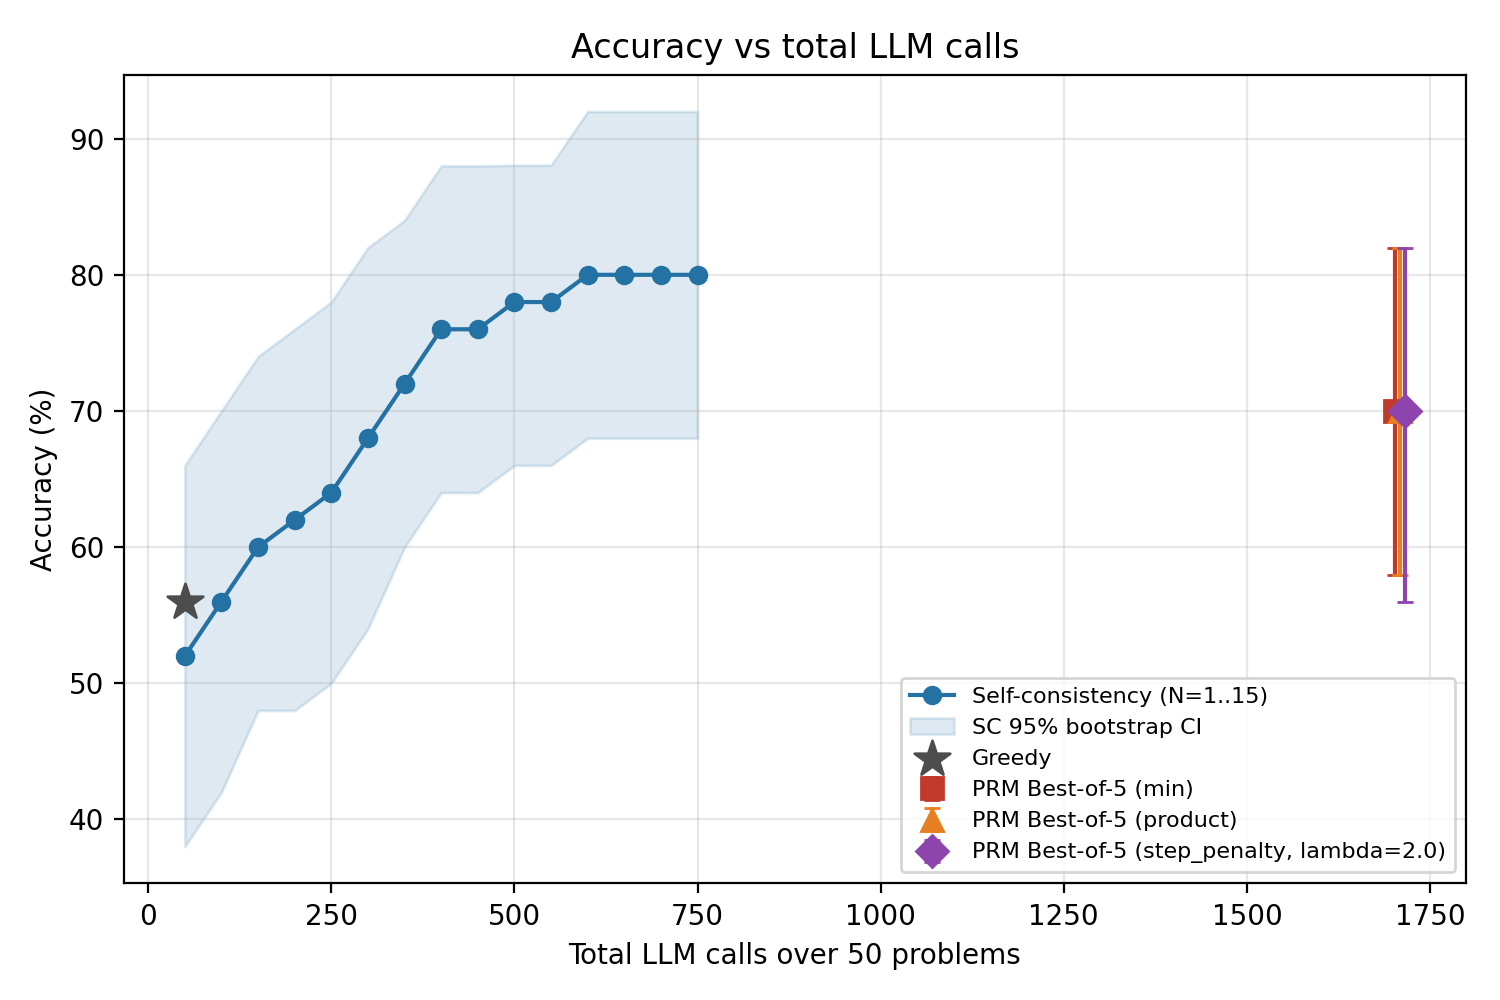

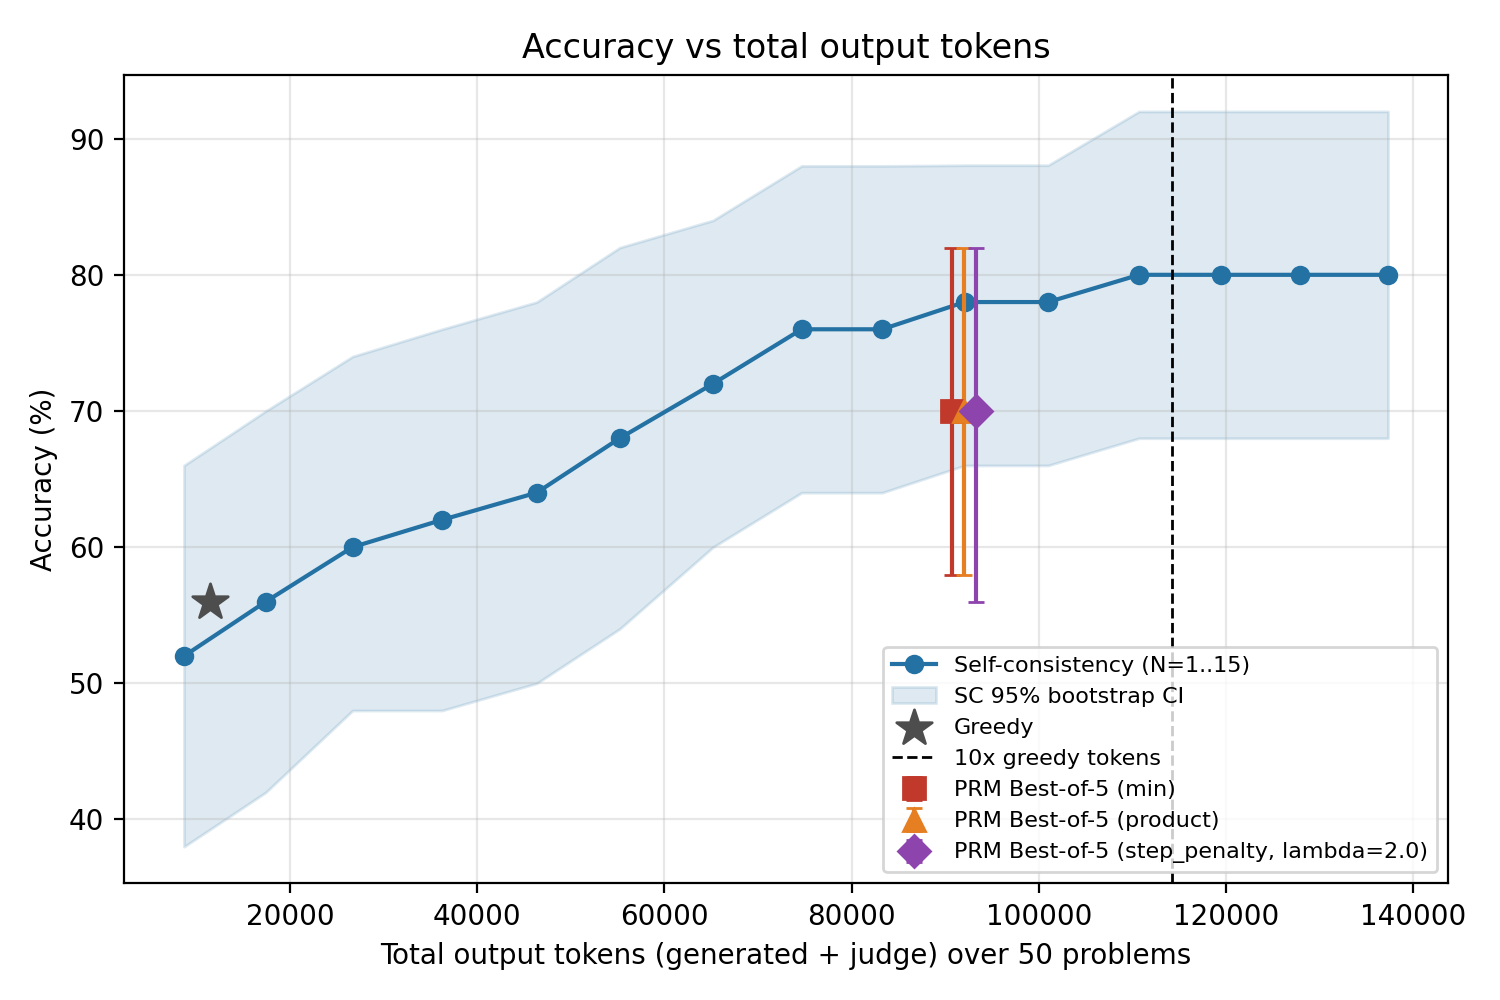

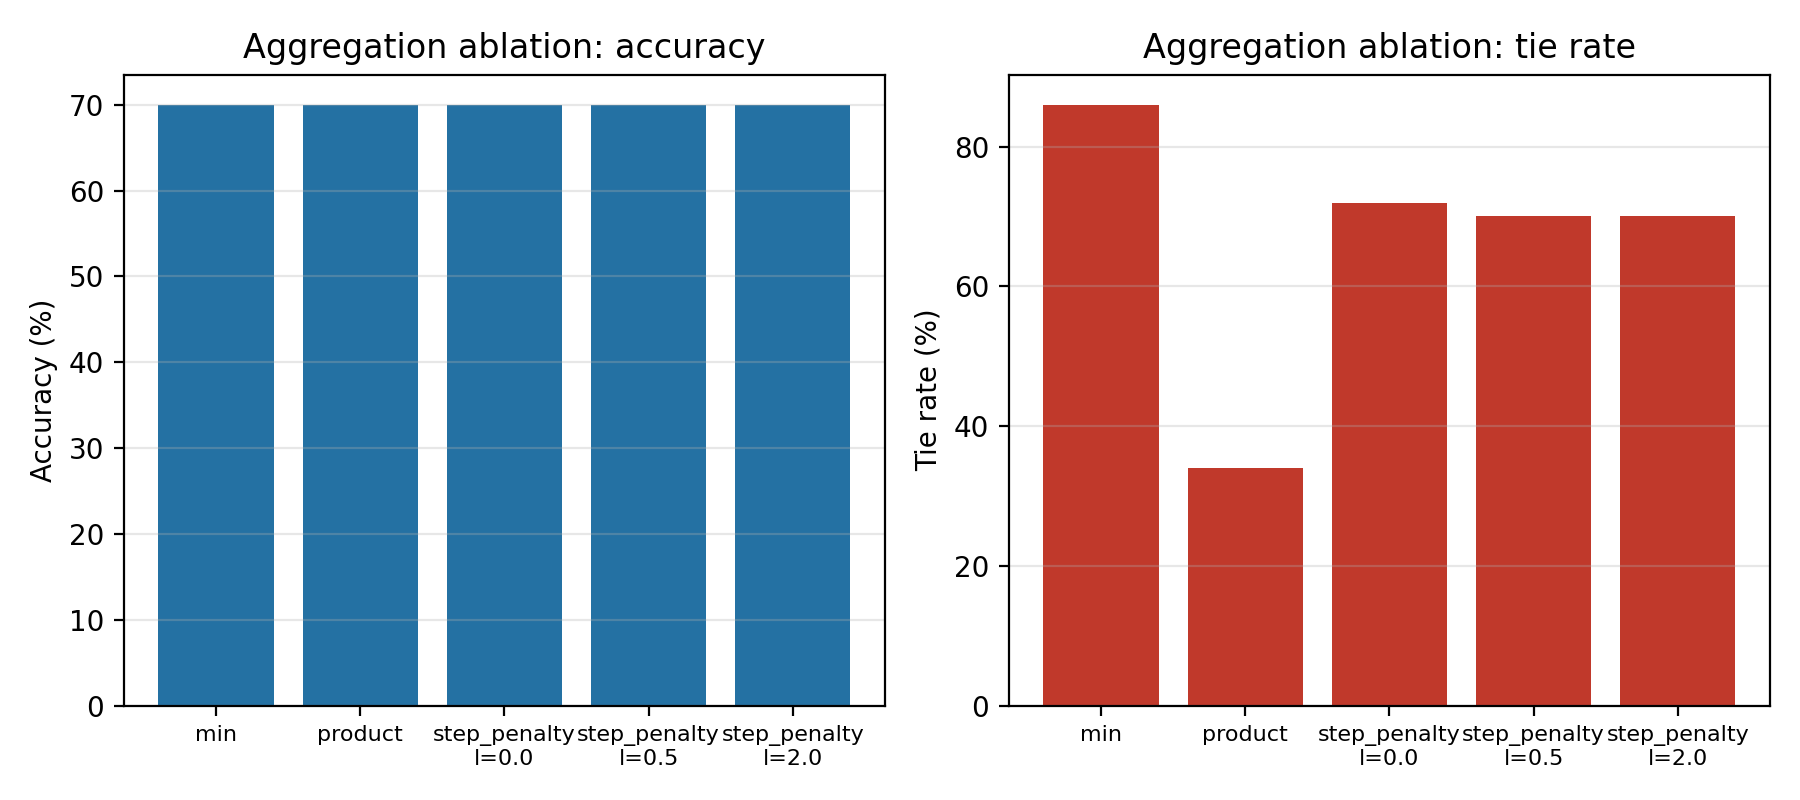

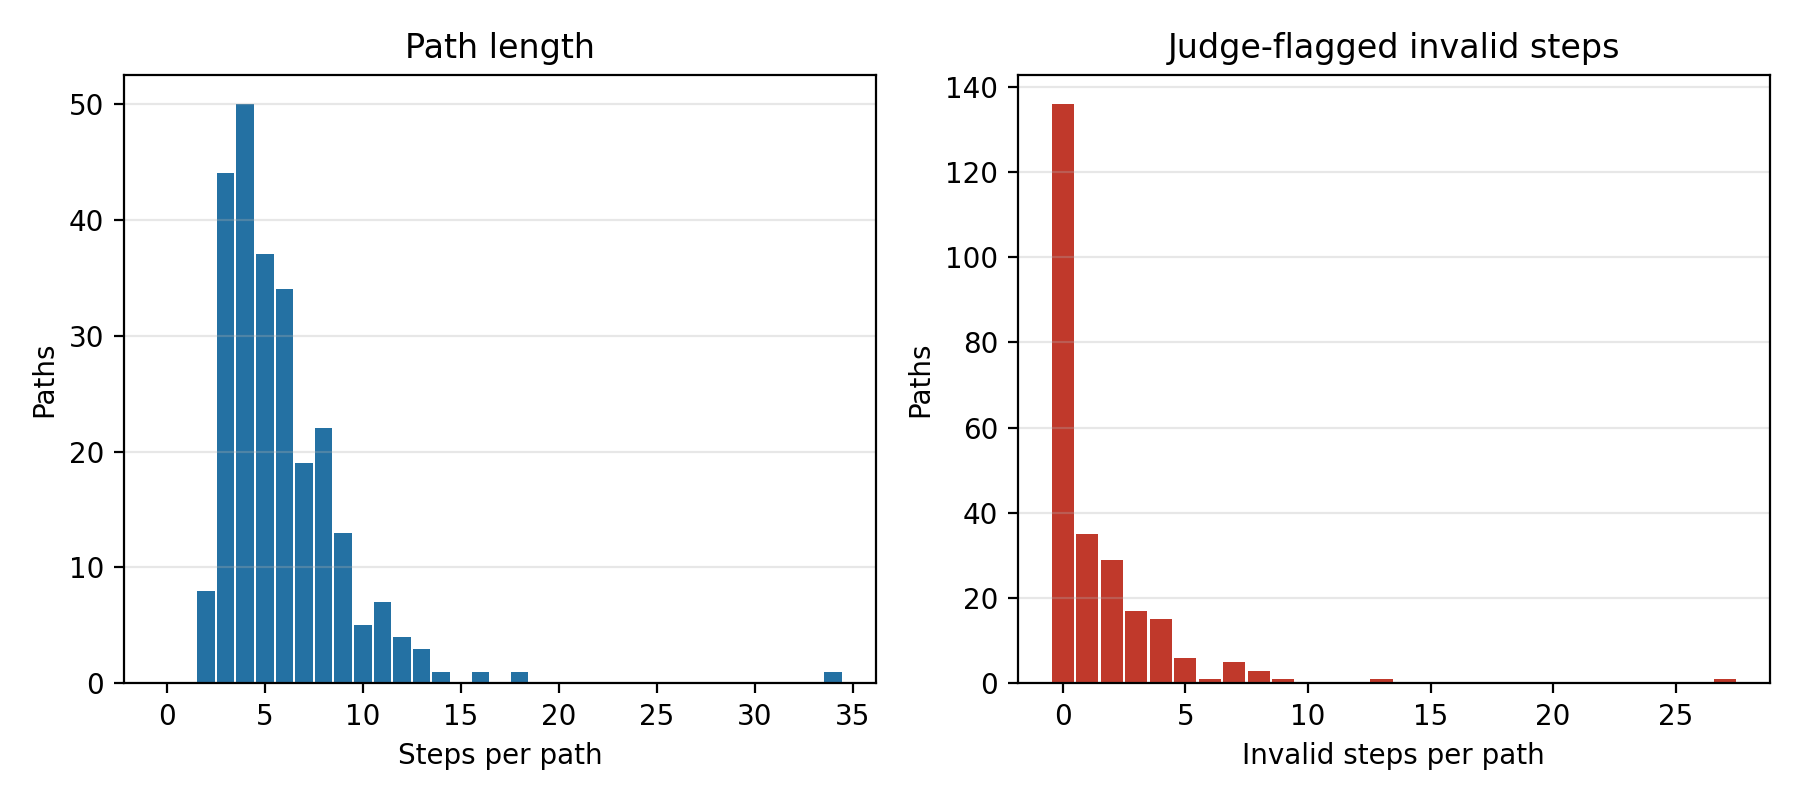

In [5]:
from IPython.display import Image, Markdown, display

display(Markdown(open("outputs/tables/report_tables.md", encoding="utf-8").read()))
for figure in sorted(glob.glob("outputs/figures/*.png")):
    display(Image(figure))